# TP2 - Réseaux de Neurones Simples (Simple ANN)

Objectifs :
- Appliquer le **perceptron simple** (seuil) aux portes logiques ET/OU/NAND et montrer son **échec sur XOR** (non-séparable).
- Reproduire le **pas-à-pas perceptron sigmoïde + MSE** vu au tableau (cas « admission »).
- Construire un **perceptron multicouche (MLP 2–2–1)** en **PyTorch** pour résoudre XOR.
- Utiliser uniquement des **données logiques**
---

## Étape 1 - Importation des bibliothèques

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

# Reproductibilité
np.set_printoptions(suppress=True, precision=8)
torch.manual_seed(0)

## Étape 2 - Préparation des données XOR

In [2]:
# Données XOR (4 couples binaires)
X = torch.tensor([[0.,0.],
                  [0.,1.],
                  [1.,0.],
                  [1.,1.]], dtype=torch.float32)
Y = torch.tensor([[0.],[1.],[1.],[0.]], dtype=torch.float32)

X, Y

(tensor([[0., 0.],
         [0., 1.],
         [1., 0.],
         [1., 1.]]),
 tensor([[0.],
         [1.],
         [1.],
         [0.]]))

## Étape 3 - Définition du modèle de réseau de neurones

In [3]:
class SimpleANN(nn.Module):
    def __init__(self, hidden=2):
        super().__init__()
        self.fc1 = nn.Linear(2, hidden)
        self.act1 = nn.Sigmoid()
        self.fc2 = nn.Linear(hidden, 1)
        self.act2 = nn.Sigmoid()
    def forward(self, x):
        z = self.act1(self.fc1(x))
        y = self.act2(self.fc2(z))
        return y

model = SimpleANN(hidden=2)
model

SimpleANN(
  (fc1): Linear(in_features=2, out_features=2, bias=True)
  (act1): Sigmoid()
  (fc2): Linear(in_features=2, out_features=1, bias=True)
  (act2): Sigmoid()
)

## Étape 4 - Entraînement du modèle

In [4]:
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=0.8, momentum=0.0)

losses = []
for epoch in range(1, 5001):
    optimizer.zero_grad()
    y_hat = model(X)
    loss = criterion(y_hat, Y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 500 == 0:
        print(f"Epoch {epoch:4d} | loss={loss.item():.6f}")


Epoch  500 | loss=0.693107
Epoch 1000 | loss=0.693020
Epoch 1500 | loss=0.692682
Epoch 2000 | loss=0.685838
Epoch 2500 | loss=0.351780
Epoch 3000 | loss=0.048923
Epoch 3500 | loss=0.024137
Epoch 4000 | loss=0.015828
Epoch 4500 | loss=0.011726
Epoch 5000 | loss=0.009294


## Étape 5 - Évaluation du modèle

Probabilités: [0.01054648 0.992242   0.9922415  0.01092184]
Prédictions : [0. 1. 1. 0.]
Exactitude  : 1.0


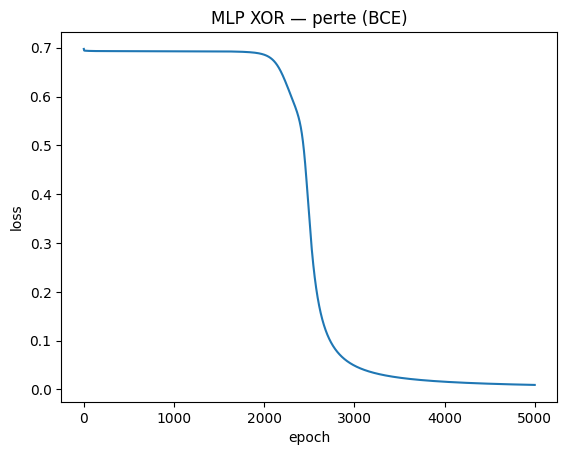

In [5]:
with torch.no_grad():
    probs = model(X)
    preds = (probs >= 0.5).float()
    acc = float((preds.eq(Y)).float().mean().item())
    print("Probabilités:", probs.numpy().ravel())
    print("Prédictions :", preds.numpy().ravel())
    print("Exactitude  :", acc)

plt.figure()
plt.plot(losses)
plt.title("MLP XOR — perte (BCE)")
plt.xlabel("epoch"); plt.ylabel("loss")
plt.show()

# Annexes
## Annexe A — Neurone MCP (seuil) pour ET / OU / NAND

In [6]:
X_bool = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)

def step(z): return (z >= 0).astype(float)
def mcp_forward(X, w, b): return step(X @ w + b).reshape(-1,1)

w_and, b_and   = np.array([1.0, 1.0]), -1.5
w_or,  b_or    = np.array([1.0, 1.0]), -0.5
w_nand, b_nand = np.array([-1.0,-1.0]),  1.5

print("MCP AND :",  mcp_forward(X_bool, w_and,  b_and).ravel())
print("MCP OR  :",  mcp_forward(X_bool, w_or,   b_or ).ravel())
print("MCP NAND:",  mcp_forward(X_bool, w_nand, b_nand).ravel())

MCP AND : [0. 0. 0. 1.]
MCP OR  : [0. 1. 1. 1.]
MCP NAND: [1. 1. 1. 0.]


## Annexe B — Perceptron simple (Rosenblatt, seuil)

In [7]:
Y_and  = np.array([[float(x[0]==1 and x[1]==1)] for x in X_bool])
Y_or   = np.array([[float(x[0]==1 or  x[1]==1)] for x in X_bool])
Y_nand = np.array([[float(not (x[0]==1 and x[1]==1))] for x in X_bool])
Y_xor  = np.array([[float((x[0]+x[1])%2==1)] for x in X_bool])

class PerceptronStep:
    def __init__(self, lr=0.2, max_epochs=100, random_state=0):
        self.lr=lr; self.max_epochs=max_epochs
        self.rng=np.random.default_rng(random_state)
        self.w=None; self.b=None
    def predict(self, X):
        return (X@self.w + self.b >= 0).astype(float).reshape(-1,1)
    def fit(self, X, y):
        n,d = X.shape
        self.w = self.rng.uniform(-1,1,size=d)
        self.b = 0.0
        hist=[]
        for ep in range(1,self.max_epochs+1):
            mistakes=0
            for i in range(n):
                xi=X[i]; yi=y[i,0]
                yhat=1.0 if (xi@self.w + self.b)>=0 else 0.0
                if yhat!=yi:
                    mistakes+=1
                    self.w = self.w + self.lr*(yi-yhat)*xi
                    self.b = self.b + self.lr*(yi-yhat)
            hist.append(mistakes)
            if mistakes==0: break
        return hist

for name, Y in [("AND",Y_and),("OR",Y_or),("NAND",Y_nand),("XOR",Y_xor)]:
    p = PerceptronStep(lr=0.2, max_epochs=100, random_state=1)
    H = p.fit(X_bool,Y); yhat=p.predict(X_bool)
    print(f"Perceptron (seuil) {name:5s} -> pred={yhat.ravel()}  acc={(yhat==Y).mean()*100:.1f}%")
    print("mal-classifications/epoch:", H, "\\n")

Perceptron (seuil) AND   -> pred=[0. 0. 0. 1.]  acc=100.0%
mal-classifications/epoch: [2, 2, 1, 0] \n
Perceptron (seuil) OR    -> pred=[0. 1. 1. 1.]  acc=100.0%
mal-classifications/epoch: [2, 1, 0] \n
Perceptron (seuil) NAND  -> pred=[1. 1. 1. 0.]  acc=100.0%
mal-classifications/epoch: [1, 3, 2, 2, 2, 2, 3, 2, 1, 0] \n
Perceptron (seuil) XOR   -> pred=[1. 1. 0. 0.]  acc=50.0%
mal-classifications/epoch: [3, 2, 2, 2, 2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4] \n


## Annexe C — Pas-à-pas perceptron sigmoïde + MSE (valeurs du cours)

In [8]:
def sigmoid(z): return 1/(1+np.exp(-z))

w = np.array([-0.165955990594852, 0.4406489868843162], dtype=float)
b = 0.0
x1 = np.array([1.0, 0.0])
y_true = 0.0
eta = 0.1

z = float(w@x1 + b)
y_pred = float(sigmoid(z))
err = y_true - y_pred
grad_w = -err * y_pred*(1-y_pred) * x1
grad_b = -err * y_pred*(1-y_pred)

w_new = w - eta*grad_w
b_new = b - eta*grad_b

print("z =", z)
print("y_pred(sigmoid) =", y_pred)
print("err =", err)
print("grad_w =", grad_w, " grad_b =", grad_b)
print("mise à jour -> w:", w_new, " b:", b_new)

z = -0.165955990594852
y_pred(sigmoid) = 0.45860596288357436
err = -0.45860596288357436
grad_w = [0.11386568 0.        ]  grad_b = 0.11386568485447962
mise à jour -> w: [-0.17734256  0.44064899]  b: -0.011386568485447963


# Remarques

- Template respecté : les Étapes 1–5 suivent exactement l’énoncé (imports, données, modèle, entraînement, évaluation).
- Niveau : aucun contenu avancé (pas d’Adam, pas de DataLoader, pas de régularisation). Juste ce que le cours couvre.
- Données : uniquement des tables logiques (ET, OU, NAND, XOR) et un pas-à-pas admission ; aucun dataset externe.
- Résultats :
  - MCP et Perceptron seuil  OK sur ET/OU/NAND, échec sur XOR.
  - Pas-à-pas sigmoïde  reproduction exacte des calculs du cours.
  - MLP 2–2–1 (PyTorch)  XOR appris à 100 %.
- Limites : paramètres fixés manuellement (lr, epochs). Sur de grands jeux, il faudrait normalisation, régularisation, etc., mais cela sort du cadre de ce TP.